# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Refuerzo, Paul Adam
- _Student No._: 2024-09465
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![1](FTs.png)
**Figure 1.** Waveforms and their Fourier Transforms

![2](FTCleaning.png)
![2*](FTCleaningSmallN.png)
**Figure 2.** Cleaning Noisy Signal Using Fourier Transform

![3](FTfilter.png)
**Figure 3.** Aliasing in the Time and Frequency Domains


### Report discussion

Figure 1 shows that the shape of a waveform determines the distribution of its frequency components. Sinusoidal signals like the sine wave are concentrated around their fundamental frequencies, while non-sinusoidal signals contain additional frequency components. In particular, the square wave exhibits multiple harmonics, whereas the Gaussian wave packet has a continuous, bell-shaped frequency spectrum.

Figure 2 demonstrates how Fourier-domain filtering can be used to recover a signal contaminated by Gaussian noise. However, the recovered waveform has a lowered amplitude, but has about the same relative amplitudes, frequencies, and extreme points as the original. Also, as figure 2 shows, reducing the number of samples N decreases the frequency resolution when the sampling interval is kept constant, making it more difficult to distinguish the signal components from noise. Consequently, there is a practical limit to how much N can be reduced while still obtaining a reliable reconstruction.

Figure 3 illustrates the effect of aliasing when sampling a signal below its Nyquist frequency. For the 10 Hz sinusoidal signal, a sampling frequency of 50 Hz satisfies the Nyquist criterion, while a sampling frequency of 8 Hz does not. The latter produces an aliased representation with an apparent frequency different from the original, demonstrating why sufficiently high sampling frequencies are necessary for accurate signal reconstruction.

---
## Section 2: Code

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

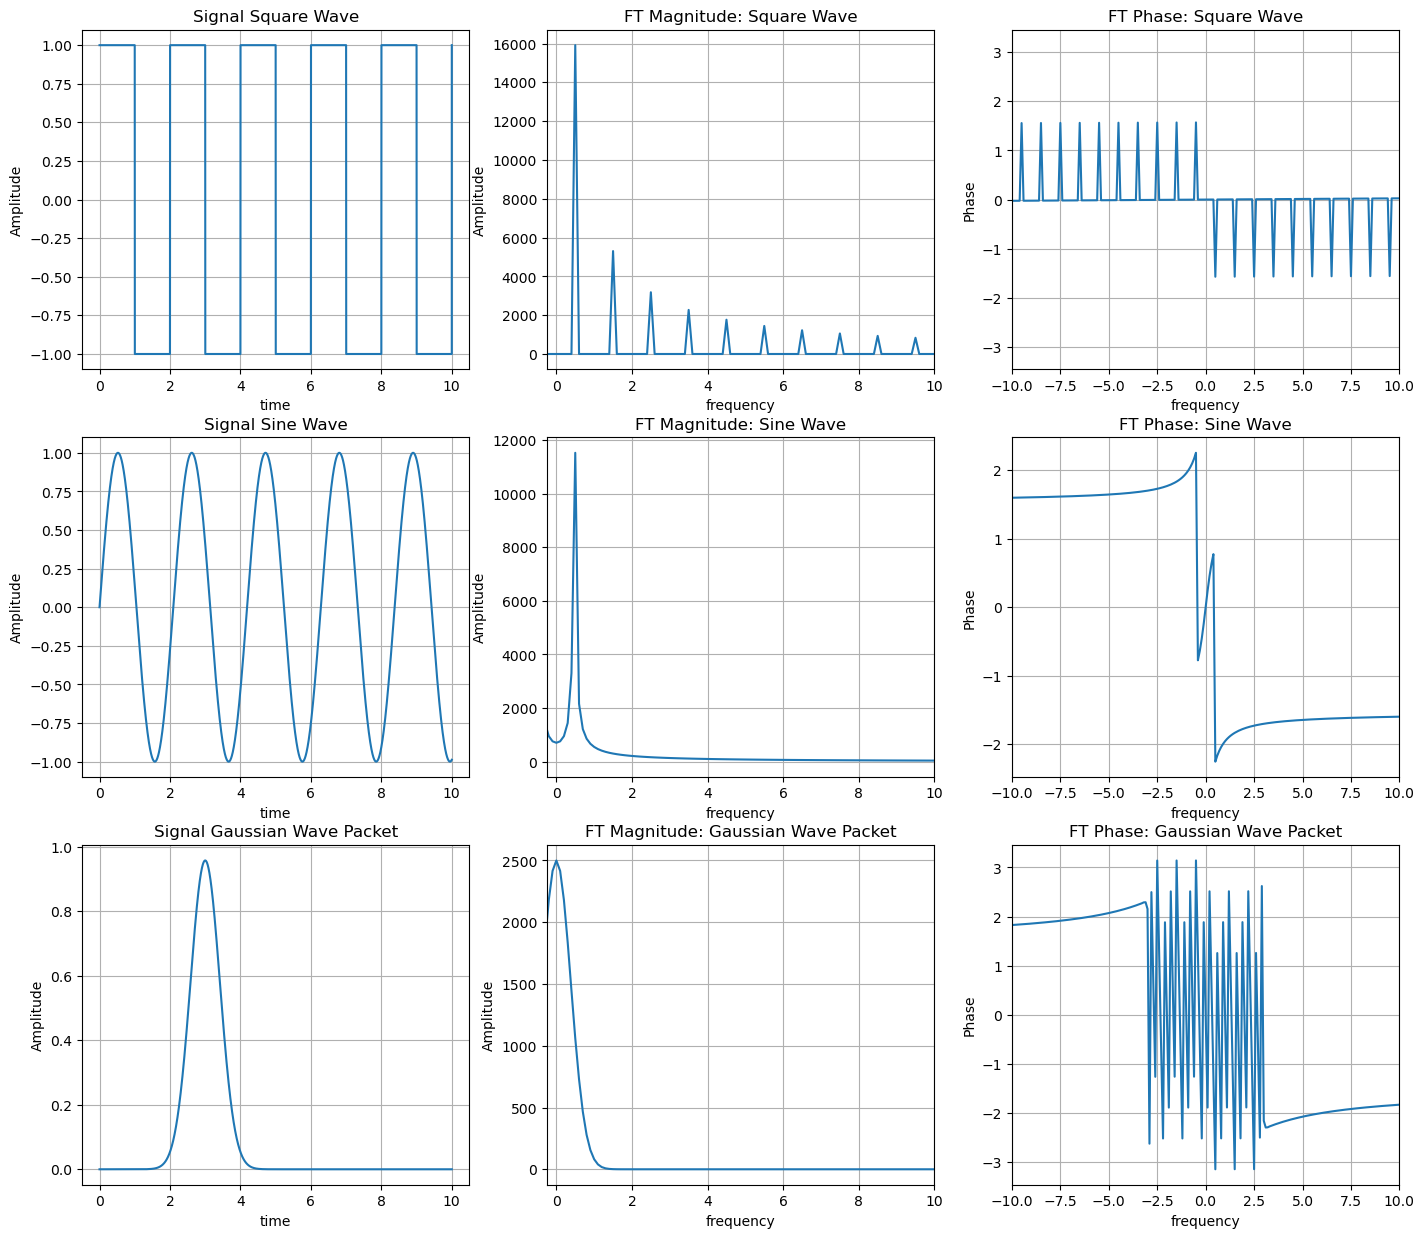

In [49]:
def square_wave(t):
    return np.piecewise(t, [(t // 1) % 2 == 0], [1.0, -1.0])

def sin_wave(t):
    return np.sin(3*t)

def gaussian_wave(t, sigma=5/12, mu=3):
    return (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((t - mu) / sigma) ** 2)

N = 25000

xs = np.linspace(0, 10, N)
dT = xs[1] - xs[0]

waves = [square_wave, sin_wave, gaussian_wave]
wave_names = ['Square Wave', 'Sine Wave', 'Gaussian Wave Packet']

fig, axs = plt.subplots(3, 3, figsize=(17, 15))

for i, (wave, wave_name) in enumerate(zip(waves, wave_names)):
    ys = wave(xs)

    freqs = np.fft.fftfreq(N, dT)
    Yk = np.fft.fft(ys)

    freqs = np.fft.fftshift(freqs)
    Yk = np.fft.fftshift(Yk)

    Yk_mag = np.abs(Yk)
    Yk_phase = np.angle(Yk)

    #Yk_phase = np.unwrap(Yk_phase)

    axs[i, 0].plot(xs, ys)
    axs[i, 0].set_title(f'Signal {wave_name}')
    axs[i, 0].set_xlabel('time')
    axs[i, 0].set_ylabel('Amplitude')
    axs[i, 0].grid()

    axs[i, 1].plot(freqs, Yk_mag)
    axs[i, 1].set_title(f'FT Magnitude: {wave_name}')
    axs[i, 1].set_xlabel('frequency')
    axs[i, 1].set_ylabel('Amplitude')
    axs[i, 1].set_xlim(-1/4 , 10)
    axs[i, 1].grid()

    axs[i, 2].plot(freqs, Yk_phase)
    axs[i, 2].set_title(f'FT Phase: {wave_name}')
    axs[i, 2].set_xlabel('frequency')
    axs[i, 2].set_ylabel('Phase')
    axs[i, 2].set_xlim(-10, 10)
    axs[i, 2].grid()

fig.savefig('FTs', dpi=300)
fig.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [113]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]


signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

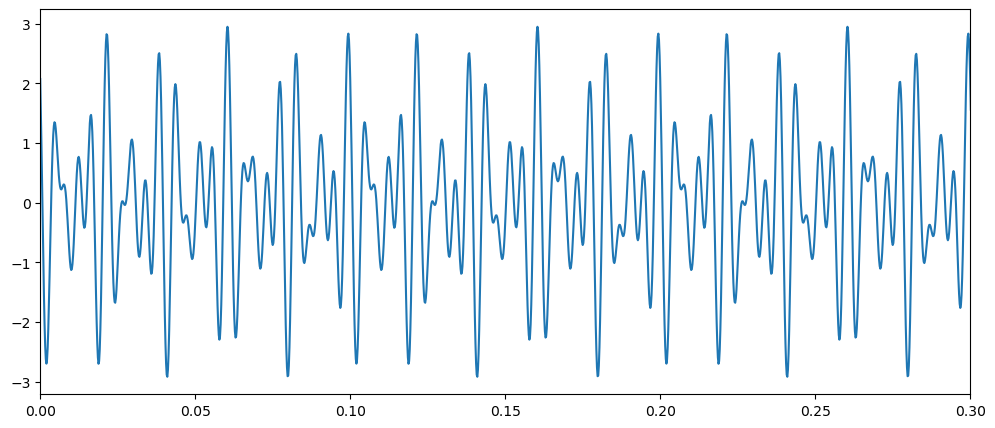

In [114]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

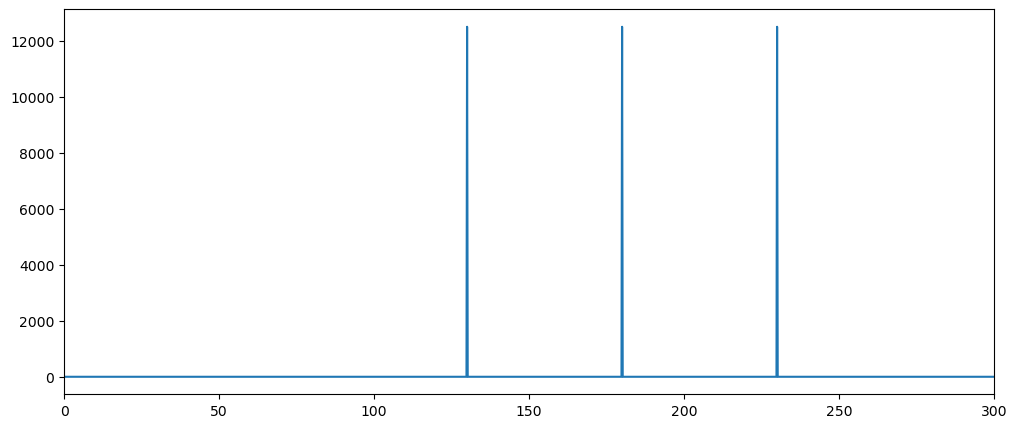

In [115]:
fourier_signal = np.fft.fft(signal_original)
fourier_freqs = np.fft.fftfreq(N, dt)

clean_fourier = abs(np.fft.fftshift(fourier_signal))
clean_freqs = np.fft.fftshift(fourier_freqs)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(clean_freqs, clean_fourier)
ax.set_xlim(0, 300)

fig.show()

In [116]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.3)

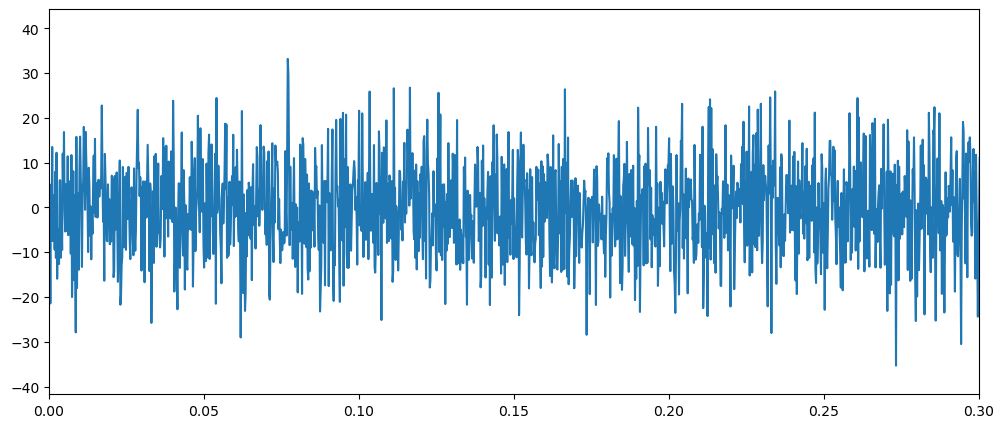

In [117]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

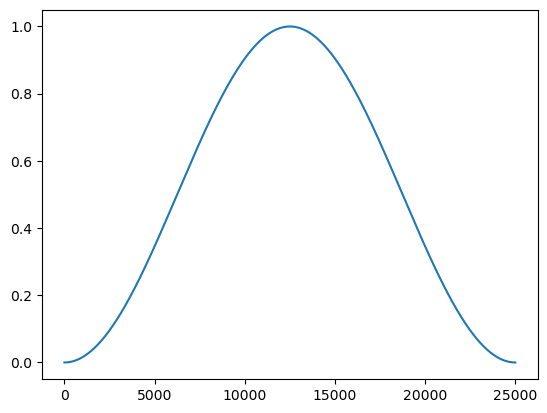

In [118]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

In [119]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


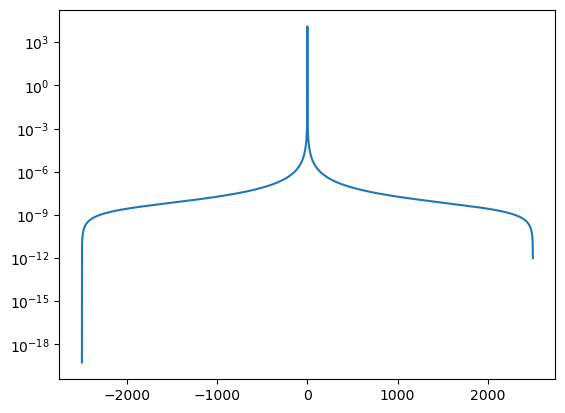

In [120]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [121]:
noisyFourier = np.fft.fft(noisy_data*window)

# noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))

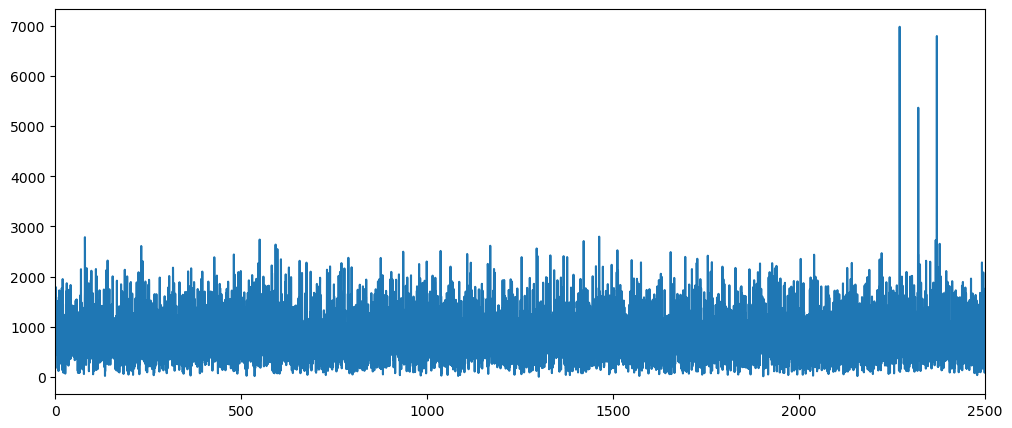

In [122]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(windowSigFreqs, abs(noisyFourier))
ax.set_xlim(0, 2500)

fig.show()

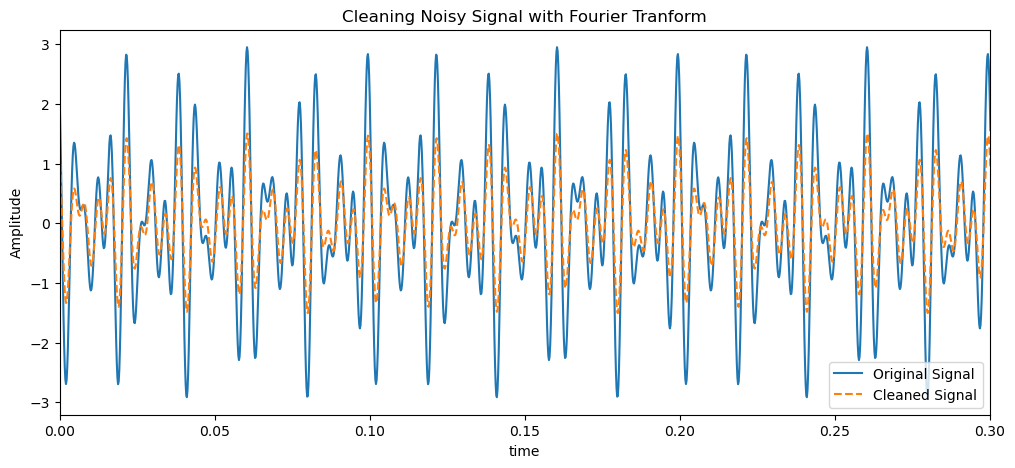

In [123]:
# Fill: Find a suitable threshold value to filter the noise in fourier space
threshold = 4800

cleaned_fourier = np.where(abs(noisyFourier) > threshold, noisyFourier, 0)
recovered_signal = np.fft.ifft(cleaned_fourier).real

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t_, signal_original, label='Original Signal')
ax.plot(t_, recovered_signal, '--', label='Cleaned Signal')
ax.set_title('Cleaning Noisy Signal with Fourier Tranform')
ax.set_xlabel('time')
ax.set_ylabel('Amplitude')
ax.set_xlim(0, 0.3)
ax.legend()

fig.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

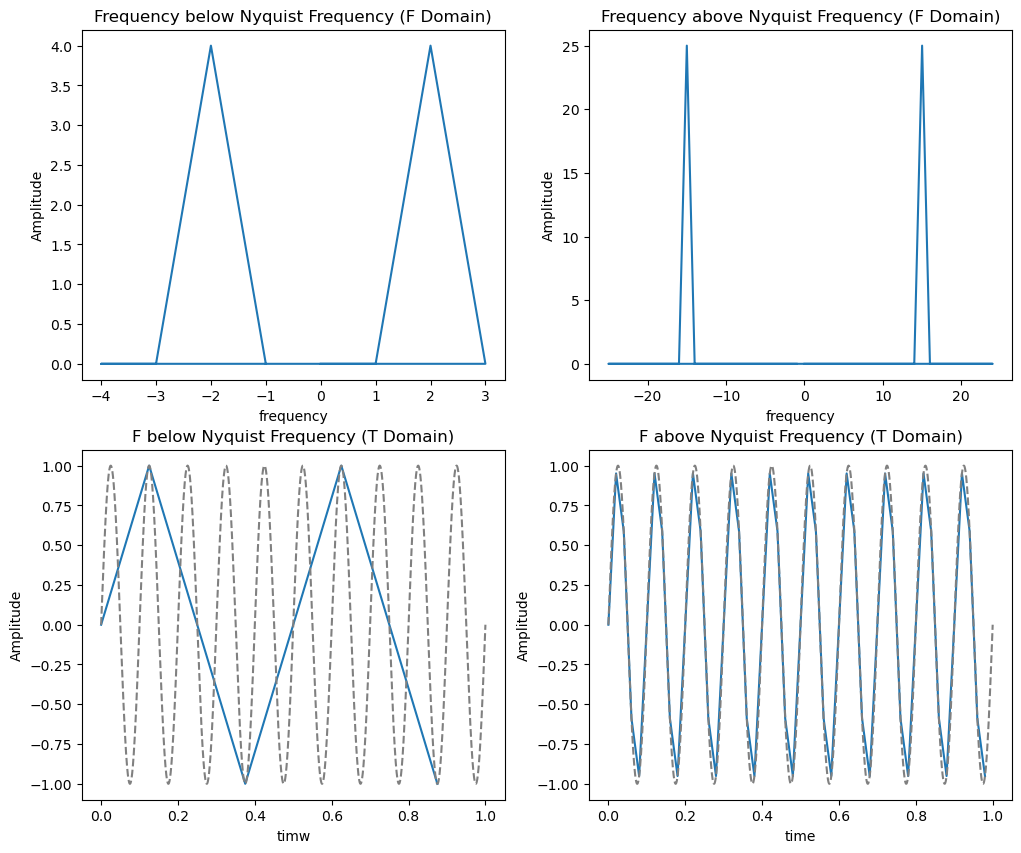

In [112]:
freq = 10
freq_high = 50
freq_low = 8
dur = 1
N = 25000

ts = np.linspace(0, dur, N)
xs = np.sin(2 * np.pi * freq * ts)

t_high = np.arange(0, dur, 1 / freq_high)
x_high = np.sin(2 * np.pi * freq * t_high)

t_low = np.arange(0, dur, 1 / freq_low)
x_low = np.sin(2 * np.pi * freq * t_low)

fft_high = np.fft.fftshift(np.fft.fft(x_high))
freq_high = np.fft.fftfreq(len(x_high), 1 / freq_high)

fft_low = np.fft.fftshift(np.fft.fft(x_low))
freq_low = np.fft.fftfreq(len(x_low), 1 / freq_low)

fig, axs = plt.subplots(2, 2, figsize=(12, 10))

axs[0, 0].plot(freq_low, abs(fft_low))
#axs[0, 0].set_xlim(0, 10)
#axs[0, 0].set_ylim(0, 6)
axs[0, 0].set_title('Frequency below Nyquist Frequency (F Domain)')
axs[0, 0].set_xlabel('frequency')
axs[0, 0].set_ylabel('Amplitude')


axs[0, 1].plot(freq_high, abs(fft_high))
#axs[0, 1].set_xlim(0, 25)
#axs[0, 1].set_ylim(0, 26)
axs[0, 1].set_title('Frequency above Nyquist Frequency (F Domain)')
axs[0, 1].set_xlabel('frequency')
axs[0, 1].set_ylabel('Amplitude')

axs[1, 0].plot(t_low, x_low)
axs[1, 0].plot(ts, xs, '--', color='gray')
axs[1, 0].set_title('F below Nyquist Frequency (T Domain)')
axs[1, 0].set_xlabel('timw')
axs[1, 0].set_ylabel('Amplitude')

axs[1, 1].plot(t_high, x_high)
axs[1, 1].plot(ts, xs, '--', color='gray')
axs[1, 1].set_title('F above Nyquist Frequency (T Domain)')
axs[1, 1].set_xlabel('time')
axs[1, 1].set_ylabel('Amplitude')

fig.show()

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [17]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

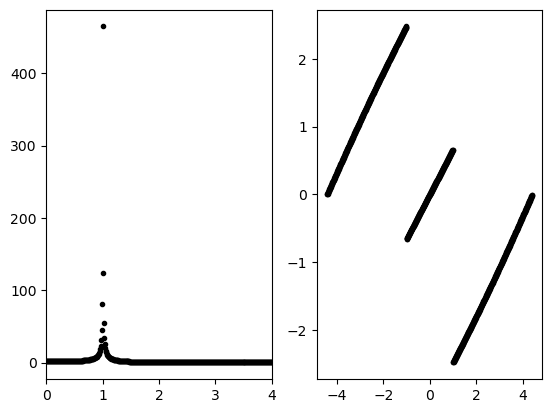

In [18]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [19]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

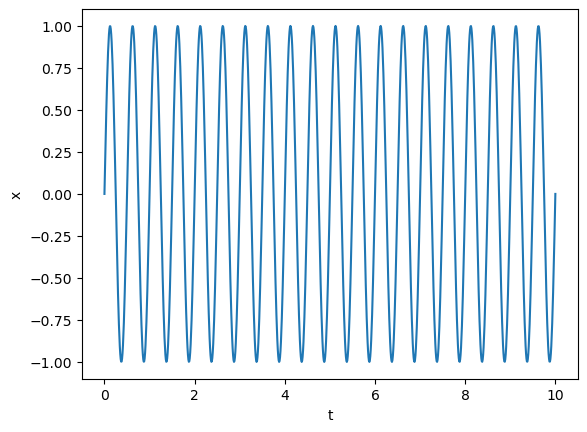

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

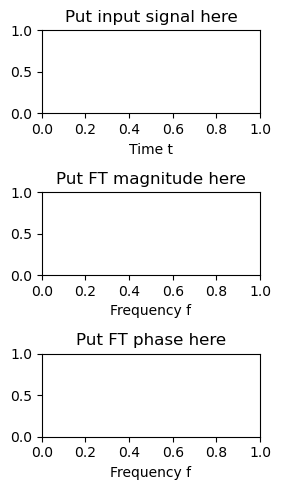

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

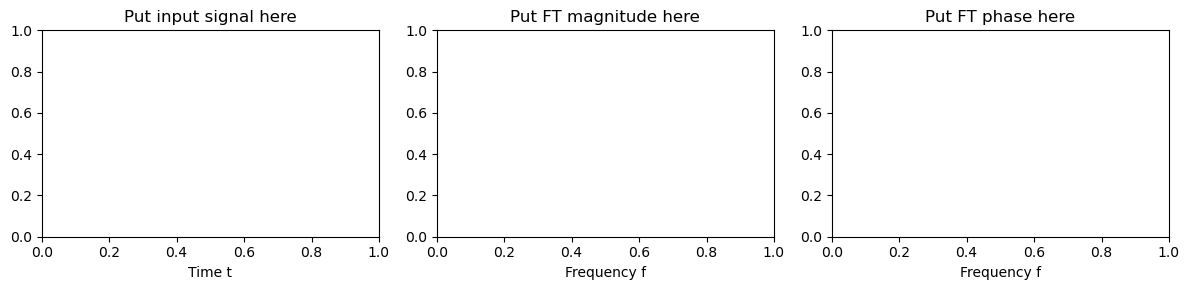

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

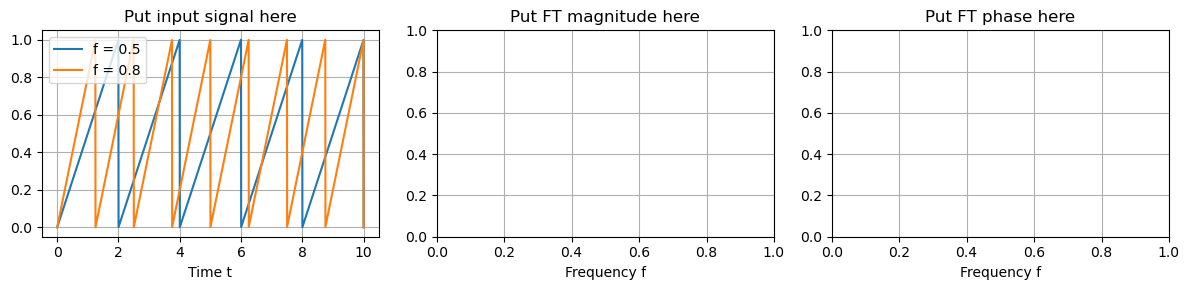

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



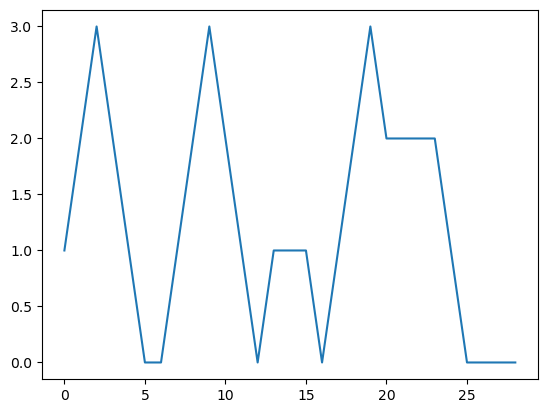

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

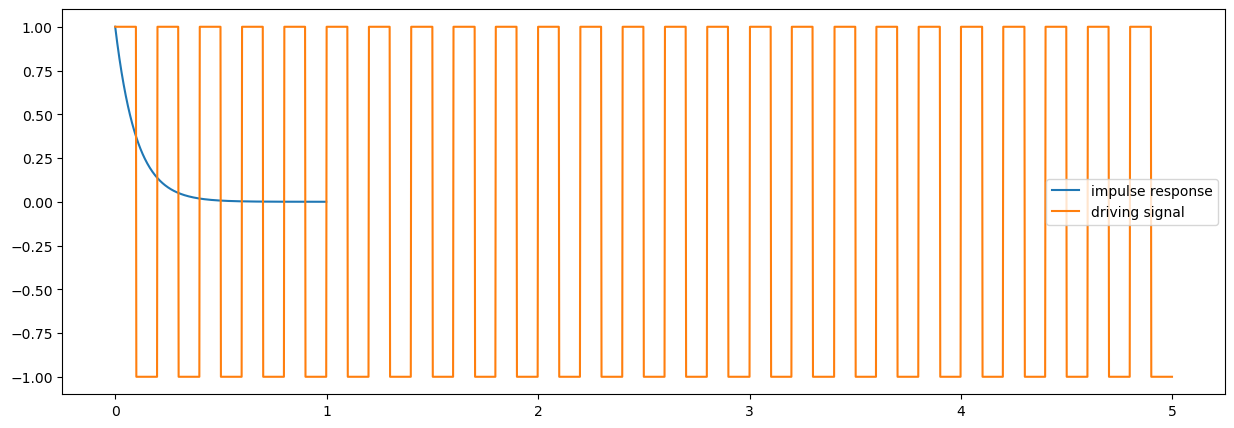

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

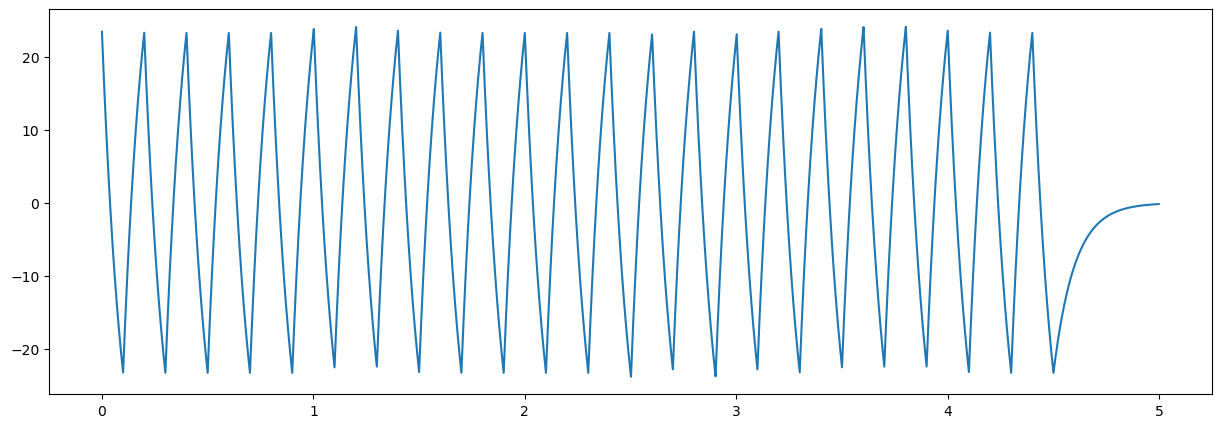

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

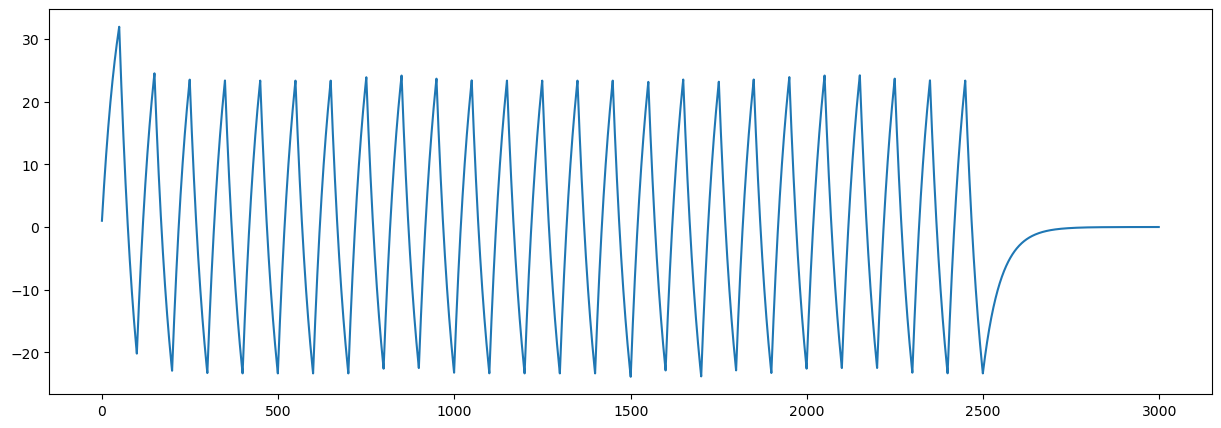

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)